## 1.- LIMPIEZA DE DATOS

In [333]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

1.1.- LIMPIEZA DATOS BITCOIN


Fuente: https://es.investing.com/crypto/bitcoin

In [334]:
# Importamos el fichero de los datos historicos del bitcoin y creamos un dataframe con formato de miles con ".", decimales con "," y fecha como str.

df_btc = pd.read_csv(
    "../data/Datos históricos del Bitcoin.csv",
    thousands=".",
    decimal=",",
    dtype={"Fecha": str}
)

In [335]:
df_btc

,Fecha,Último,Apertura,Máximo,Mínimo,Vol.,% var.
0,10.11.2026,73210.9,75326.9,75404.0,72934.3,"54,32K","-2,81%"
1,09.11.2026,75330.6,74791.8,75572.7,73743.7,"60,11K","0,74%"
2,08.11.2026,74774.2,75847.4,76183.3,74002.5,"33,03K","-1,41%"
3,07.11.2026,75847.4,75823.1,76182.2,75574.9,"21,52K","0,03%"
4,06.11.2026,75823.7,76063.5,76378.1,74955.1,"60,70K","-0,31%"
...,...,...,...,...,...,...,...
4753,05.11.2013,251.3,238.2,258.9,229.0,"45,10K","5,52%"
4754,04.11.2013,238.2,224.0,239.0,221.9,"18,06K","6,32%"
4755,03.11.2013,224.0,211.7,226.9,212.1,"12,27K","5,82%"
4756,02.11.2013,211.7,213.4,214.9,211.0,"4,88K","-0,82%"


In [336]:
df_btc.info()

<class 'pandas.DataFrame'>
RangeIndex: 4758 entries, 0 to 4757
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Fecha     4758 non-null   str    
 1   Último    4758 non-null   float64
 2   Apertura  4758 non-null   float64
 3   Máximo    4758 non-null   float64
 4   Mínimo    4758 non-null   float64
 5   Vol.      4758 non-null   str    
 6   % var.    4758 non-null   str    
dtypes: float64(4), str(3)
memory usage: 260.3 KB


In [337]:
# La fecha va como índice y con su formato correspondiente

df_btc["Fecha"] = pd.to_datetime(df_btc["Fecha"], format="%d.%m.%Y")
df_btc = df_btc.set_index("Fecha")
df_btc = df_btc.sort_index()


In [338]:
# Se elimina el simbolo %, se cambia la "," por el "." de la columna var. y se combierte en un float.

df_btc["% var."] = df_btc["% var."].str.replace("%", "").str.replace(",", ".").astype(float)

In [339]:
# Se eliminan Máximo, Mínimo y Vol. por no ser necesarias para el análisis.

df_btc = df_btc.drop(columns=["Máximo", "Mínimo", "Vol."])
df_btc = df_btc.sort_index()


In [340]:
df_btc

,Último,Apertura,% var.
Fecha,,,
2013-11-01,213.4,211.2,1.07
2013-11-02,211.7,213.4,-0.82
2013-11-03,224.0,211.7,5.82
2013-11-04,238.2,224.0,6.32
2013-11-05,251.3,238.2,5.52
...,...,...,...
2026-11-06,75823.7,76063.5,-0.31
2026-11-07,75847.4,75823.1,0.03
2026-11-08,74774.2,75847.4,-1.41


1.2.- LIMPIEZA DE DATOS SP500

Fuente: https://es.investing.com/indices/us-spx-500

In [341]:
# Importamos el fichero de los datos historicos del SP500 y creamos un dataframe con formato de miles con ".", decimales con "," y fecha como str.

df_sp500 = pd.read_csv(
    "../data/Datos históricos del S&P 500.csv",
    thousands=".",
    decimal=",",
    dtype={"Fecha": str}
)

In [342]:
# La fecha va como índice y con su formato correspondiente

df_sp500["Fecha"] = pd.to_datetime(df_sp500["Fecha"], format="%d.%m.%Y")
df_sp500 = df_sp500.set_index("Fecha")
df_sp500 = df_sp500.sort_index()

In [343]:
# Se eliminan Máximo, Mínimo y Vol. por no ser necesarias para el análisis.

df_sp500 = df_sp500.drop(columns=["Máximo", "Mínimo", "Vol."])

df_sp500 = df_sp500.sort_index()
df_sp500.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4234 entries, 2010-01-12 to 2026-11-10
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Último    4234 non-null   float64
 1   Apertura  4234 non-null   float64
 2   % var.    4234 non-null   str    
dtypes: float64(2), str(1)
memory usage: 132.3 KB


In [344]:
# Se elimina el simbolo %, se cambia la "," por el "." de la columna var. y se combierte en un float.

df_sp500["% var."] = df_sp500["% var."].str.replace("%", "").str.replace(",", ".").astype(float)

In [345]:
df_sp500

,Último,Apertura,% var.
Fecha,,,
2010-01-12,1136.20,1143.80,-0.94
2010-01-13,1145.70,1137.30,0.84
2010-01-14,1148.50,1145.70,0.24
2010-01-15,1136.00,1147.70,-1.09
2010-01-19,1150.20,1136.00,1.25
...,...,...,...
2026-11-04,7688.62,7635.81,1.58
2026-11-05,7353.73,7678.72,-4.36
2026-11-06,7376.86,7377.65,0.31


1.3.- LIMPIEZA DATOS ORO

Fuente: https://es.investing.com/currencies/xau-usd

In [346]:
df_oro = pd.read_csv(
    "../data/Datos históricos XAU_USD.csv",
    thousands=".",
    decimal=",",
    dtype={"Fecha": str}
)

In [347]:
# La fecha va como índice y con su formato correspondiente

df_oro["Fecha"] = pd.to_datetime(df_oro["Fecha"], format="%d.%m.%Y")
df_oro = df_oro.set_index("Fecha")
df_oro = df_oro.sort_index()

In [348]:
# Se elimina el simbolo %, se cambia la "," por el "." de la columna var. y se combierte en un float.

df_oro["% var."] = df_oro["% var."].str.replace("%", "").str.replace(",", ".").astype(float)

In [349]:
# Se eliminan Máximo, Mínimo y Vol. por no ser necesarias para el análisis.

df_oro = df_oro.drop(columns=["Máximo", "Mínimo", "Vol."])
df_oro = df_oro.sort_index()
df_oro.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4340 entries, 2010-01-12 to 2026-11-10
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Último    4340 non-null   float64
 1   Apertura  4340 non-null   float64
 2   % var.    4340 non-null   float64
dtypes: float64(3)
memory usage: 135.6 KB


In [350]:
df_oro

,Último,Apertura,% var.
Fecha,,,
2010-01-12,1128.02,1151.73,-2.06
2010-01-13,1137.93,1128.02,0.88
2010-01-14,1142.73,1137.93,0.42
2010-01-15,1131.02,1142.73,-1.02
2010-01-18,1133.87,1131.62,0.25
...,...,...,...
2026-11-04,4060.02,3928.48,3.35
2026-11-05,4087.71,4059.93,0.68
2026-11-06,4066.63,4087.48,-0.52


1.4.- LIMPIEZA DATOS FED

Fuente: https://fred.stlouisfed.org/series/fedfunds

In [351]:
df_fed = pd.read_csv("../data/FEDFUNDS.csv", dtype={"observation_date": str})
df_fed = df_fed.rename(columns={"observation_date": "Fecha"})
df_fed.info()
df_fed

<class 'pandas.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Fecha     202 non-null    str    
 1   FEDFUNDS  202 non-null    float64
dtypes: float64(1), str(1)
memory usage: 3.3 KB


,Fecha,FEDFUNDS
0,2010-01-01,0.11
1,2010-02-01,0.13
2,2010-03-01,0.16
3,2010-04-01,0.20
4,2010-05-01,0.20
...,...,...
197,2026-06-01,3.63
198,2026-07-01,3.63
199,2026-08-01,3.63
200,2026-09-01,3.75


1.5.- TABLAS CON LAS MISMAS FECHAS DE DATOS

In [352]:
# Fechas comunes: solo los días que existen en BTC, S&P 500 y oro, a partir del 01-01-2014.
# El Bitcoin cotiza todos los dias pero el SP500 y el Oro no, cierra fines de semana y festivos.
# La FED es mensual (día 1 de cada mes): su tipo se mantiene todo el mes, así que se rellena hacia delante (ffill) en esas fechas.

df_fed["Fecha"] = pd.to_datetime(df_fed["Fecha"], format="%Y-%m-%d")
df_fed = df_fed.set_index("Fecha").sort_index()

fechas_comunes = df_btc.index.intersection(df_sp500.index).intersection(df_oro.index)
fechas_comunes = fechas_comunes[fechas_comunes >= "2014-01-01"]

df_btc = df_btc.loc[fechas_comunes]
df_sp500 = df_sp500.loc[fechas_comunes]
df_oro = df_oro.loc[fechas_comunes]
df_fed = df_fed.reindex(df_fed.index.union(fechas_comunes)).ffill().loc[fechas_comunes]

for nombre, df in [("BTC", df_btc), ("S&P 500", df_sp500), ("Oro", df_oro), ("FED", df_fed)]:
    print(nombre, df.shape, df.index.min().date(), "->", df.index.max().date())

BTC (3226, 3) 2014-01-02 -> 2026-11-10
S&P 500 (3226, 3) 2014-01-02 -> 2026-11-10
Oro (3226, 3) 2014-01-02 -> 2026-11-10
FED (3226, 1) 2014-01-02 -> 2026-11-10


In [353]:
df_btc


,Último,Apertura,% var.
Fecha,,,
2014-01-02,856.9,815.9,5.02
2014-01-03,884.3,856.9,3.19
2014-01-06,1012.7,1014.7,-0.21
2014-01-07,879.9,1012.7,-13.11
2014-01-08,938.8,879.9,6.70
...,...,...,...
2026-11-04,80476.7,77427.3,3.95
2026-11-05,76061.6,80487.1,-5.49
2026-11-06,75823.7,76063.5,-0.31


In [354]:
df_sp500

,Último,Apertura,% var.
Fecha,,,
2014-01-02,1832.00,1845.90,-0.89
2014-01-03,1831.40,1833.20,-0.03
2014-01-06,1826.80,1832.30,-0.25
2014-01-07,1837.90,1828.70,0.61
2014-01-08,1837.50,1837.90,-0.02
...,...,...,...
2026-11-04,7688.62,7635.81,1.58
2026-11-05,7353.73,7678.72,-4.36
2026-11-06,7376.86,7377.65,0.31


In [355]:
df_oro

,Último,Apertura,% var.
Fecha,,,
2014-01-02,1224.38,1205.09,1.60
2014-01-03,1236.90,1224.38,1.02
2014-01-06,1238.10,1236.90,0.10
2014-01-07,1232.12,1238.10,-0.48
2014-01-08,1225.97,1232.12,-0.50
...,...,...,...
2026-11-04,4060.02,3928.48,3.35
2026-11-05,4087.71,4059.93,0.68
2026-11-06,4066.63,4087.48,-0.52


In [356]:
df_fed

,FEDFUNDS
Fecha,
2014-01-02,0.07
2014-01-03,0.07
2014-01-06,0.07
2014-01-07,0.07
2014-01-08,0.07
...,...
2026-11-04,3.88
2026-11-05,3.88
2026-11-06,3.88


1.5.- TABLA DE LAS CRISIS FINANCIERAS DESDE 2014

In [357]:
# Tabla de crisis: nombre, fecha de inicio y fecha de fin (del máximo al mínimo del S&P 500).

crisis = pd.DataFrame({
    "crisis": ["Crash bursátil chino", "Brexit", "Subida de tipos FED 2018", "COVID",
               "Inflación y subida de tipos", "Crisis bancaria EE. UU.", "Carry trade del yen",
               "Aranceles EE. UU.", "Conflicto con Irán"],
    "inicio": ["2015-08-17", "2016-06-23", "2018-09-20", "2020-02-19",
               "2022-01-03", "2023-03-08", "2024-07-16", "2025-02-19", "2026-02-01"],
    "fin":    ["2015-08-25", "2016-06-27", "2018-12-24", "2020-03-23",
               "2022-10-12", "2023-03-13", "2024-08-05", "2025-04-08", "2026-02-28"]
})

crisis["inicio"] = pd.to_datetime(crisis["inicio"])
crisis["fin"] = pd.to_datetime(crisis["fin"])
crisis

,crisis,inicio,fin
0,Crash bursátil chino,2015-08-17,2015-08-25
1,Brexit,2016-06-23,2016-06-27
2,Subida de tipos FED 2018,2018-09-20,2018-12-24
3,COVID,2020-02-19,2020-03-23
4,Inflación y subida de tipos,2022-01-03,2022-10-12
5,Crisis bancaria EE. UU.,2023-03-08,2023-03-13
6,Carry trade del yen,2024-07-16,2024-08-05
7,Aranceles EE. UU.,2025-02-19,2025-04-08
8,Conflicto con Irán,2026-02-01,2026-02-28


1.6 UNION DE TABLAS

In [358]:
# Unión de las cuatro tablas por fecha.

df_tabla_todo = pd.concat([df_btc, df_sp500, df_oro, df_fed], axis=1)
df_tabla_todo.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 3226 entries, 2014-01-02 to 2026-11-10
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Último    3226 non-null   float64
 1   Apertura  3226 non-null   float64
 2   % var.    3226 non-null   float64
 3   Último    3226 non-null   float64
 4   Apertura  3226 non-null   float64
 5   % var.    3226 non-null   float64
 6   Último    3226 non-null   float64
 7   Apertura  3226 non-null   float64
 8   % var.    3226 non-null   float64
 9   FEDFUNDS  3226 non-null   float64
dtypes: float64(10)
memory usage: 277.2 KB


In [359]:
df_tabla_todo

,Último,Apertura,% var.,Último,Apertura,% var.,Último,Apertura,% var.,FEDFUNDS
Fecha,,,,,,,,,,
2014-01-02,856.9,815.9,5.02,1832.00,1845.90,-0.89,1224.38,1205.09,1.60,0.07
2014-01-03,884.3,856.9,3.19,1831.40,1833.20,-0.03,1236.90,1224.38,1.02,0.07
2014-01-06,1012.7,1014.7,-0.21,1826.80,1832.30,-0.25,1238.10,1236.90,0.10,0.07
2014-01-07,879.9,1012.7,-13.11,1837.90,1828.70,0.61,1232.12,1238.10,-0.48,0.07
2014-01-08,938.8,879.9,6.70,1837.50,1837.90,-0.02,1225.97,1232.12,-0.50,0.07
...,...,...,...,...,...,...,...,...,...,...
2026-11-04,80476.7,77427.3,3.95,7688.62,7635.81,1.58,4060.02,3928.48,3.35,3.88
2026-11-05,76061.6,80487.1,-5.49,7353.73,7678.72,-4.36,4087.71,4059.93,0.68,3.88
2026-11-06,75823.7,76063.5,-0.31,7376.86,7377.65,0.31,4066.63,4087.48,-0.52,3.88


### **HIPÓTESIS 1:** EN LAS CRISIS FINANCIERAS DESDE 2013, EL BITCOIN CAYÓ JUNTO CON LA BOLSA

***1.- ¿Cómo se comportó el precio del bitcoin en las crisis financieras ocurridas desde 2013?***

In [360]:

import seaborn as sns
import matplotlib.pyplot as plt



In [361]:
# Hacemos copia de la tabla limpia de bitcoin e incluimos con una columna que indicará la crisis de cada día.

df_btc_h1 = df_btc.copy()
df_btc_h1["crisis"] = "Sin crisis"
df_btc_h1

,Último,Apertura,% var.,crisis
Fecha,,,,
2014-01-02,856.9,815.9,5.02,Sin crisis
2014-01-03,884.3,856.9,3.19,Sin crisis
2014-01-06,1012.7,1014.7,-0.21,Sin crisis
2014-01-07,879.9,1012.7,-13.11,Sin crisis
2014-01-08,938.8,879.9,6.70,Sin crisis
...,...,...,...,...
2026-11-04,80476.7,77427.3,3.95,Sin crisis
2026-11-05,76061.6,80487.1,-5.49,Sin crisis
2026-11-06,75823.7,76063.5,-0.31,Sin crisis


In [362]:
# Se recorre la tabla de crisis y se marcan los días que caen entre su inicio y su fin.

for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]
    df_btc_h1.loc[inicio:fin, "crisis"] = nombre

In [363]:
df_btc_h1["crisis"].value_counts()

crisis
Sin crisis                     2860
Inflación y subida de tipos     194
Subida de tipos FED 2018         66
Aranceles EE. UU.                35
COVID                            24
Conflicto con Irán               19
Carry trade del yen              14
Crash bursátil chino              7
Crisis bancaria EE. UU.           4
Brexit                            3
Name: count, dtype: int64

In [364]:
# Precio de cierre del primer y del último día de cada crisis, y variación entre ambos.

tabla_btc = df_btc_h1[df_btc_h1["crisis"] != "Sin crisis"].groupby("crisis").agg(
    precio_inicio=("Último", "first"),
    precio_fin=("Último", "last")
)
tabla_btc["variacion_%"] = (tabla_btc["precio_fin"] - tabla_btc["precio_inicio"]) / tabla_btc["precio_inicio"] * 100
tabla_btc = tabla_btc.reindex(crisis["crisis"])
tabla_btc

,precio_inicio,precio_fin,variacion_%
crisis,,,
Crash bursátil chino,257.1,220.5,-14.235706
Brexit,620.8,644.7,3.849871
Subida de tipos FED 2018,6489.2,4026.1,-37.956913
COVID,9609.4,6468.9,-32.681541
Inflación y subida de tipos,46430.2,19154.8,-58.744955
Crisis bancaria EE. UU.,21710.8,24114.4,11.070988
Carry trade del yen,65049.7,53979.0,-17.018833
Aranceles EE. UU.,96644.8,76312.5,-21.038173
Conflicto con Irán,78720.6,65870.2,-16.324063


Grafico con Seaborn

In [365]:
sns.set_theme(style="whitegrid")

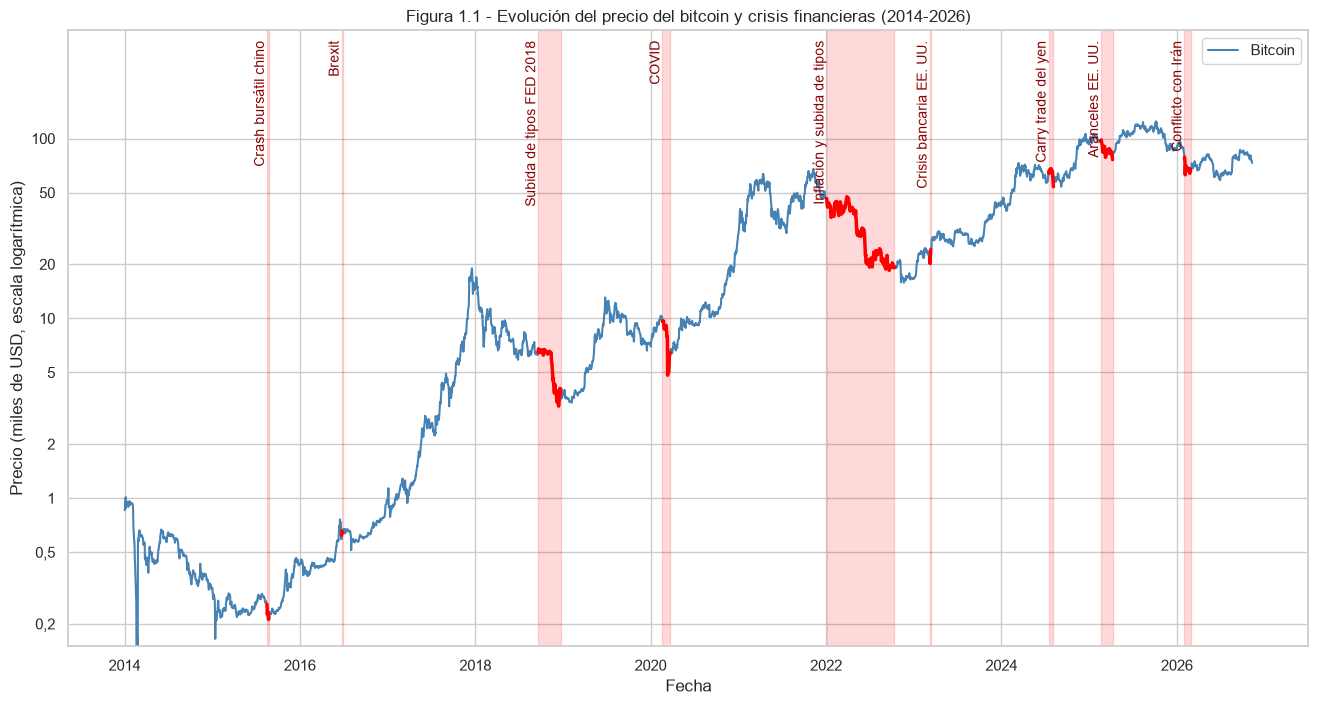

In [366]:
# Figura 1.1: evolución del precio del bitcoin (en miles de USD) con los periodos de crisis marcados.

btc_miles = df_btc["Último"] / 1000

plt.figure(figsize=(16, 8))

# Línea completa del precio
sns.lineplot(x=btc_miles.index, y=btc_miles, color="steelblue", label="Bitcoin")

for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]

    # Franja sombreada del periodo de crisis
    plt.axvspan(inicio, fin, color="red", alpha=0.15)

    # Tramo del precio durante la crisis, en rojo
    tramo = btc_miles.loc[inicio:fin]
    sns.lineplot(x=tramo.index, y=tramo, color="red", linewidth=2.5)

    # Nombre de la crisis, en vertical en la parte superior
    plt.text(inicio, 350, nombre, rotation=90, va="top", ha="right", color="darkred", fontsize=10)

plt.yscale("log")
plt.ylim(0.15, 400)
plt.yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100],
           ["0,2", "0,5", "1", "2", "5", "10", "20", "50", "100"])

plt.title("Figura 1.1 - Evolución del precio del bitcoin y crisis financieras (2014-2026)")
plt.xlabel("Fecha")
plt.ylabel("Precio (miles de USD, escala logarítmica)")
plt.show()

***2.- ¿Cómo se comportó el oro, el activo refugio por excelencia, en esos mismos momentos?***

In [367]:
# Copia de la tabla del oro para la H1, con una columna que indicará la crisis de cada día.

df_oro_h1 = df_oro.copy()
df_oro_h1["crisis"] = "Sin crisis"

In [368]:
for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]
    df_oro_h1.loc[inicio:fin, "crisis"] = nombre

df_oro_h1["crisis"].value_counts()

crisis
Sin crisis                     2860
Inflación y subida de tipos     194
Subida de tipos FED 2018         66
Aranceles EE. UU.                35
COVID                            24
Conflicto con Irán               19
Carry trade del yen              14
Crash bursátil chino              7
Crisis bancaria EE. UU.           4
Brexit                            3
Name: count, dtype: int64

In [369]:
tabla_oro = df_oro_h1[df_oro_h1["crisis"] != "Sin crisis"].groupby("crisis").agg(
    precio_inicio=("Último", "first"),
    precio_fin=("Último", "last")
)
tabla_oro["variacion_%"] = (tabla_oro["precio_fin"] - tabla_oro["precio_inicio"]) / tabla_oro["precio_inicio"] * 100
tabla_oro = tabla_oro.reindex(crisis["crisis"])
tabla_oro

,precio_inicio,precio_fin,variacion_%
crisis,,,
Crash bursátil chino,1117.53,1140.65,2.068848
Brexit,1255.58,1324.40,5.481132
Subida de tipos FED 2018,1207.16,1269.03,5.125253
COVID,1611.69,1553.12,-3.634074
Inflación y subida de tipos,1801.19,1673.20,-7.105858
Crisis bancaria EE. UU.,1813.83,1913.63,5.502169
Carry trade del yen,2468.93,2409.89,-2.391319
Aranceles EE. UU.,2932.64,2983.78,1.743821
Conflicto con Irán,4666.27,5277.90,13.107471


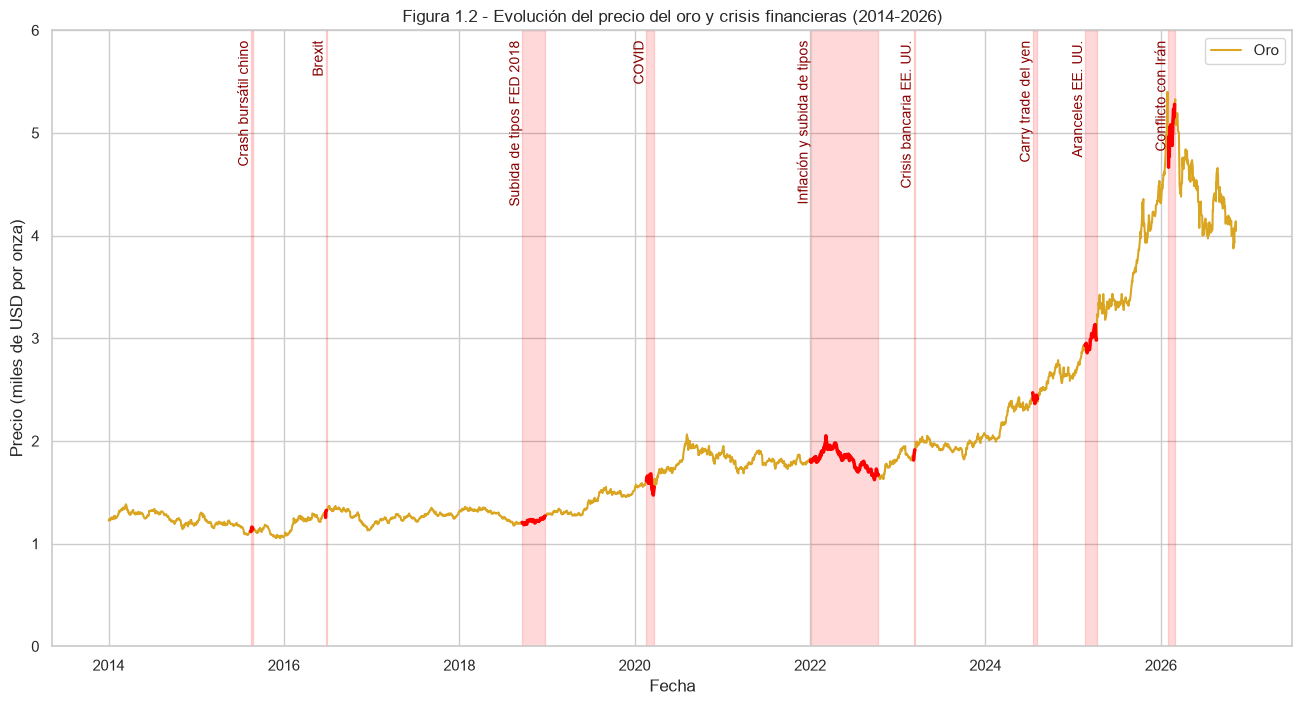

In [370]:
oro_miles = df_oro["Último"] / 1000

plt.figure(figsize=(16, 8))
sns.lineplot(x=oro_miles.index, y=oro_miles, color="goldenrod", label="Oro")

for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]

    plt.axvspan(inicio, fin, color="red", alpha=0.15)
    tramo = oro_miles.loc[inicio:fin]
    sns.lineplot(x=tramo.index, y=tramo, color="red", linewidth=2.5)
    plt.text(inicio, 5.9, nombre, rotation=90, va="top", ha="right", color="darkred", fontsize=10)

plt.ylim(0, 6)
plt.title("Figura 1.2 - Evolución del precio del oro y crisis financieras (2014-2026)")
plt.xlabel("Fecha")
plt.ylabel("Precio (miles de USD por onza)")
plt.show()

***3.- ¿Y la renta variable (S&P 500)?***

In [371]:
# Copia de la tabla del S&P 500 para la H1, con una columna que indicará la crisis de cada día.

df_sp500_h1 = df_sp500.copy()
df_sp500_h1["crisis"] = "Sin crisis"

In [372]:
for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]
    df_sp500_h1.loc[inicio:fin, "crisis"] = nombre

df_sp500_h1["crisis"].value_counts()

crisis
Sin crisis                     2860
Inflación y subida de tipos     194
Subida de tipos FED 2018         66
Aranceles EE. UU.                35
COVID                            24
Conflicto con Irán               19
Carry trade del yen              14
Crash bursátil chino              7
Crisis bancaria EE. UU.           4
Brexit                            3
Name: count, dtype: int64

In [373]:
tabla_sp500 = df_sp500_h1[df_sp500_h1["crisis"] != "Sin crisis"].groupby("crisis").agg(
    precio_inicio=("Último", "first"),
    precio_fin=("Último", "last")
)
tabla_sp500["variacion_%"] = (tabla_sp500["precio_fin"] - tabla_sp500["precio_inicio"]) / tabla_sp500["precio_inicio"] * 100
tabla_sp500 = tabla_sp500.reindex(crisis["crisis"])
tabla_sp500

,precio_inicio,precio_fin,variacion_%
crisis,,,
Crash bursátil chino,2102.40,1867.60,-11.168189
Brexit,2113.30,2000.50,-5.337624
Subida de tipos FED 2018,2930.80,2351.10,-19.779582
COVID,3386.20,2237.40,-33.925935
Inflación y subida de tipos,4796.60,3577.03,-25.425718
Crisis bancaria EE. UU.,3992.01,3855.76,-3.413068
Carry trade del yen,5667.20,5186.33,-8.485143
Aranceles EE. UU.,6144.15,4982.77,-18.902208
Conflicto con Irán,6976.44,6878.88,-1.398421


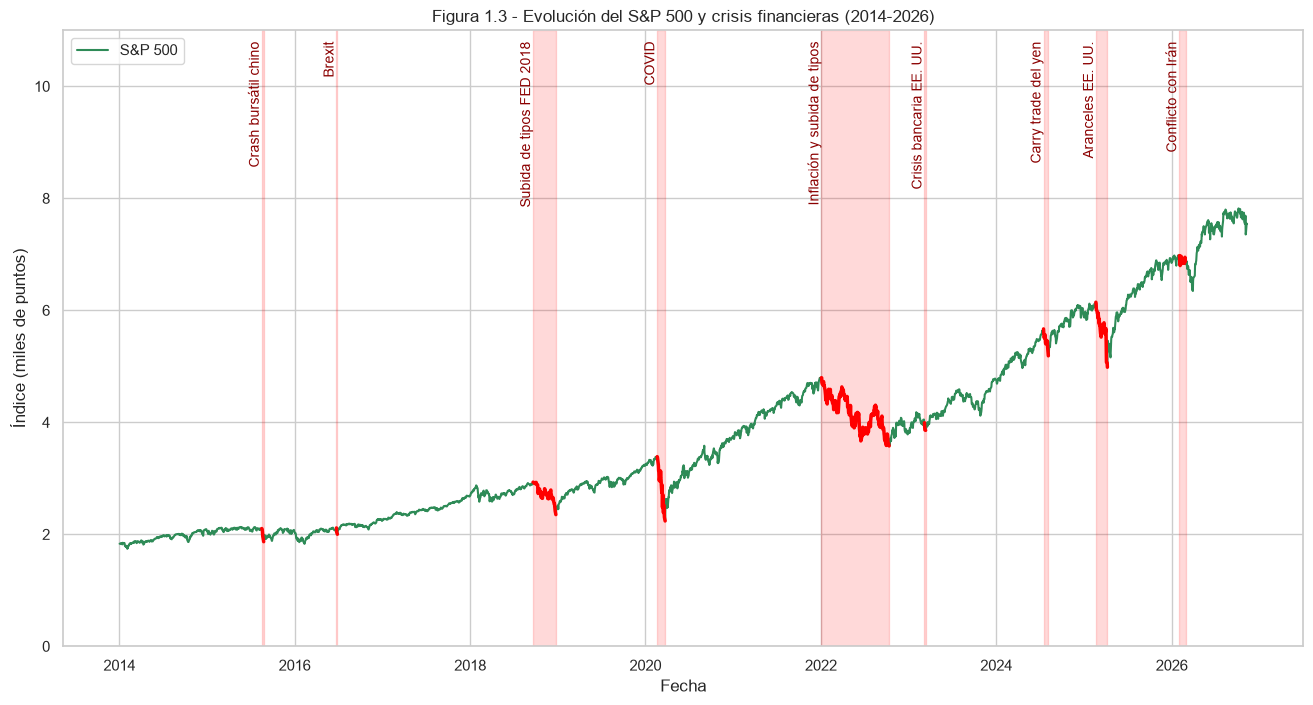

In [374]:
sp500_miles = df_sp500["Último"] / 1000

plt.figure(figsize=(16, 8))
sns.lineplot(x=sp500_miles.index, y=sp500_miles, color="seagreen", label="S&P 500")

for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]

    plt.axvspan(inicio, fin, color="red", alpha=0.15)
    tramo = sp500_miles.loc[inicio:fin]
    sns.lineplot(x=tramo.index, y=tramo, color="red", linewidth=2.5)
    plt.text(inicio, 10.8, nombre, rotation=90, va="top", ha="right", color="darkred", fontsize=10)

plt.ylim(0, 11)
plt.title("Figura 1.3 - Evolución del S&P 500 y crisis financieras (2014-2026)")
plt.xlabel("Fecha")
plt.ylabel("Índice (miles de puntos)")
plt.show()

# Comparacion de los tres activos en las epocas de crisis

In [375]:
# Tabla resumen H1: variación de cada activo en cada crisis (%).

resumen_h1 = pd.DataFrame({
    "bitcoin": tabla_btc["variacion_%"],
    "sp500": tabla_sp500["variacion_%"],
    "oro": tabla_oro["variacion_%"]
}).round(2)
resumen_h1

,bitcoin,sp500,oro
crisis,,,
Crash bursátil chino,-14.24,-11.17,2.07
Brexit,3.85,-5.34,5.48
Subida de tipos FED 2018,-37.96,-19.78,5.13
COVID,-32.68,-33.93,-3.63
Inflación y subida de tipos,-58.74,-25.43,-7.11
Crisis bancaria EE. UU.,11.07,-3.41,5.50
Carry trade del yen,-17.02,-8.49,-2.39
Aranceles EE. UU.,-21.04,-18.90,1.74
Conflicto con Irán,-16.32,-1.40,13.11


In [376]:
resumen_h1.mean().round(2)

bitcoin   -20.34
sp500     -14.21
oro         2.21
dtype: float64

***En 7 de las 9 crisis el bitcoin cayó a la vez que el S&P 500, y de media cayó más que la bolsa (-20,3 % frente a -14,2 %). El oro solo cayó en 3 y de media subió un 2,2 %.
La hipótesis 1 se confirma: el bitcoin no actuó como refugio.***

### **HIPÓTESIS 2:** EL BITCOIN SE COMPORTA MÁS COMO LA RENTA VARIABLE (S&P 500) QUE COMO EL ORO

1.- ¿Se han movido el bitcoin y el oro de la misma manera en este periodo?

In [377]:
# Precios de cierre de los tres activos en las fechas comunes.

precios = pd.DataFrame({
    "bitcoin": df_btc["Último"],
    "sp500": df_sp500["Último"],
    "oro": df_oro["Último"]
})

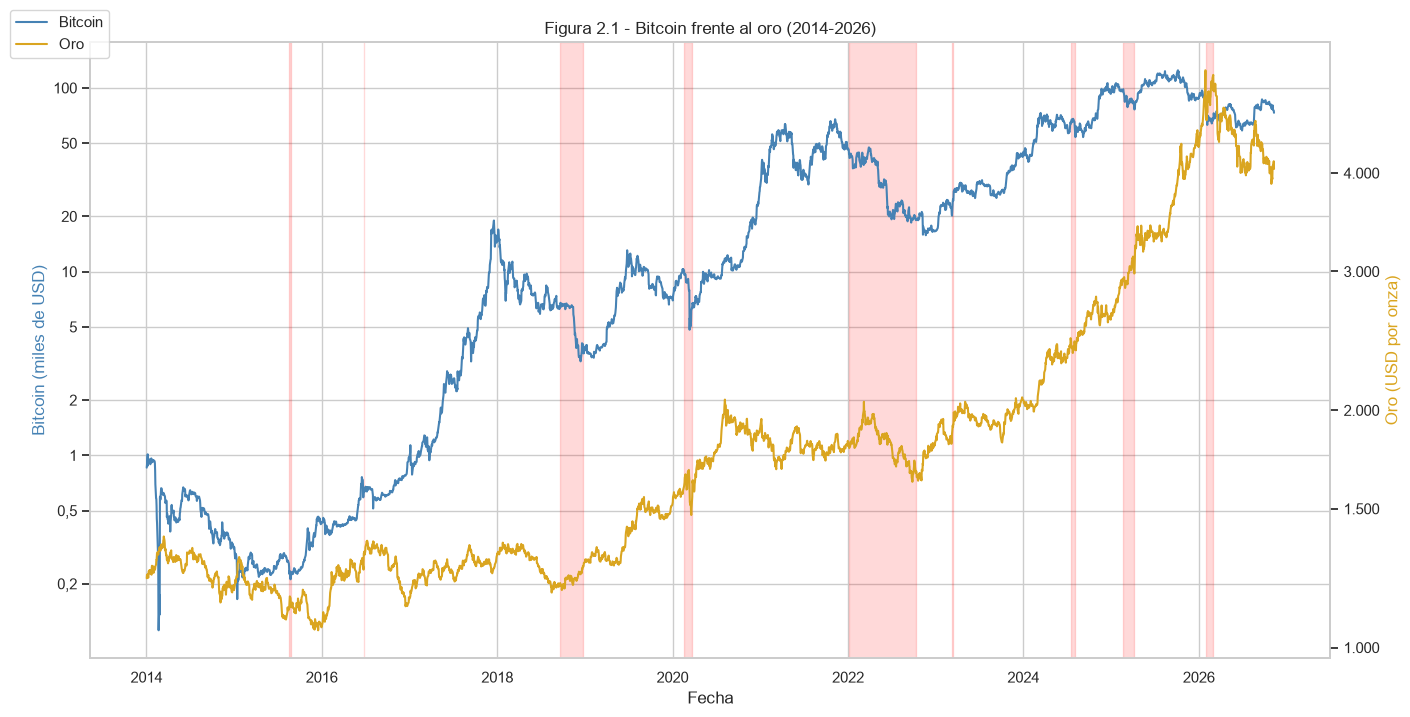

In [378]:
# Figura 2.1: bitcoin (eje izquierdo) frente al oro (eje derecho), datos diarios.

fig, ax1 = plt.subplots(figsize=(16, 8))

# Eje izquierdo: bitcoin en miles de USD
ax1.plot(df_btc.index, df_btc["Último"] / 1000, color="steelblue", linewidth=1.5, label="Bitcoin")
ax1.set_yscale("log")
ax1.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
ax1.set_yticklabels(["0,2", "0,5", "1", "2", "5", "10", "20", "50", "100"])
ax1.minorticks_off()
ax1.set_ylabel("Bitcoin (miles de USD)", color="steelblue")

# Eje derecho: oro en USD por onza
ax2 = ax1.twinx()
ax2.plot(df_oro.index, df_oro["Último"], color="goldenrod", linewidth=1.5, label="Oro")
ax2.set_yscale("log")
ax2.set_yticks([1000, 1500, 2000, 3000, 4000])
ax2.set_yticklabels(["1.000", "1.500", "2.000", "3.000", "4.000"])
ax2.minorticks_off()
ax2.set_ylabel("Oro (USD por onza)", color="goldenrod")
ax2.grid(False)

# Periodos de crisis
for i in range(len(crisis)):
    ax1.axvspan(crisis["inicio"][i], crisis["fin"][i], color="red", alpha=0.15)

ax1.set_title("Figura 2.1 - Bitcoin frente al oro (2014-2026)")
ax1.set_xlabel("Fecha")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
plt.show()

2.- ¿Y el bitcoin y el S&P 500?

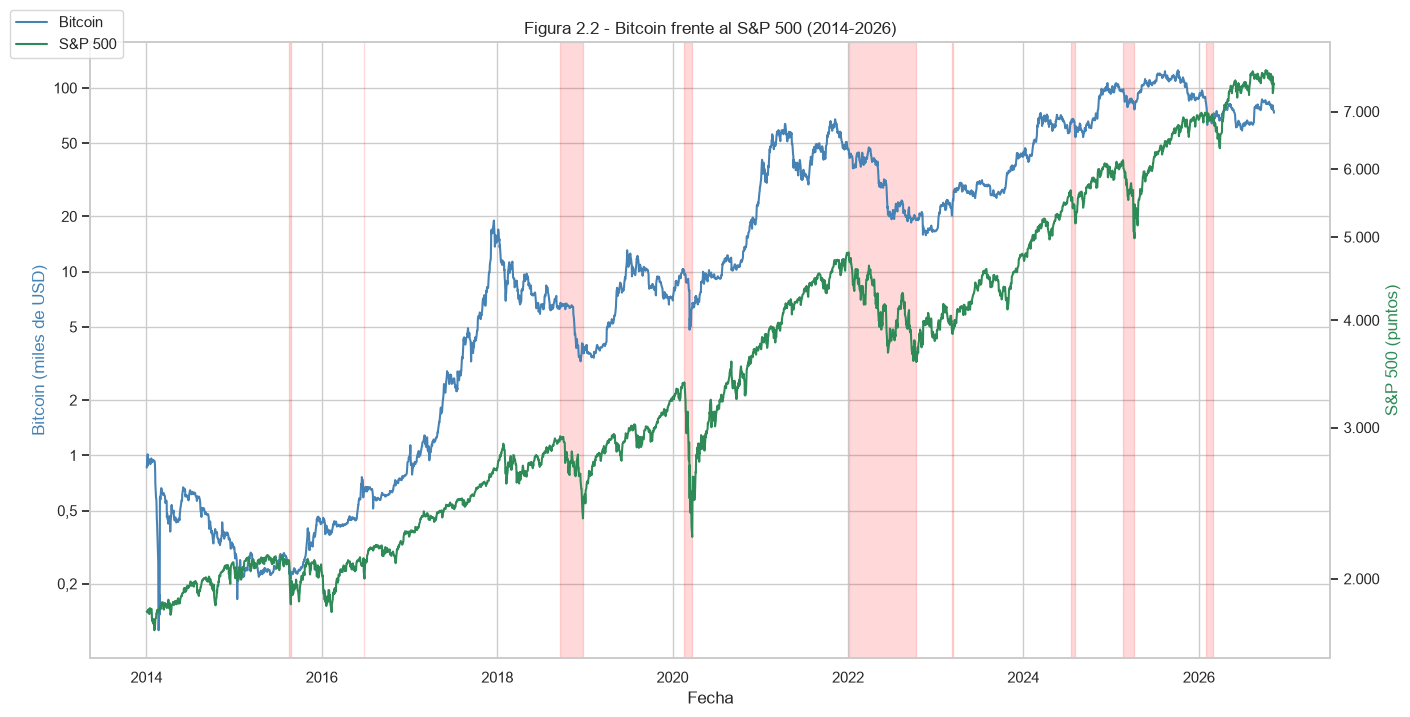

In [379]:
# Figura 2.2: bitcoin (eje izquierdo) frente al S&P 500 (eje derecho), datos diarios.

fig, ax1 = plt.subplots(figsize=(16, 8))

# Eje izquierdo: bitcoin en miles de USD
ax1.plot(df_btc.index, df_btc["Último"] / 1000, color="steelblue", linewidth=1.5, label="Bitcoin")
ax1.set_yscale("log")
ax1.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
ax1.set_yticklabels(["0,2", "0,5", "1", "2", "5", "10", "20", "50", "100"])
ax1.minorticks_off()
ax1.set_ylabel("Bitcoin (miles de USD)", color="steelblue")

# Eje derecho: S&P 500 en puntos
ax2 = ax1.twinx()
ax2.plot(df_sp500.index, df_sp500["Último"], color="seagreen", linewidth=1.5, label="S&P 500")
ax2.set_yscale("log")
ax2.set_yticks([2000, 3000, 4000, 5000, 6000, 7000])
ax2.set_yticklabels(["2.000", "3.000", "4.000", "5.000", "6.000", "7.000"])
ax2.minorticks_off()
ax2.set_ylabel("S&P 500 (puntos)", color="seagreen")
ax2.grid(False)

# Periodos de crisis
for i in range(len(crisis)):
    ax1.axvspan(crisis["inicio"][i], crisis["fin"][i], color="red", alpha=0.15)

ax1.set_title("Figura 2.2 - Bitcoin frente al S&P 500 (2014-2026)")
ax1.set_xlabel("Fecha")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
plt.show()


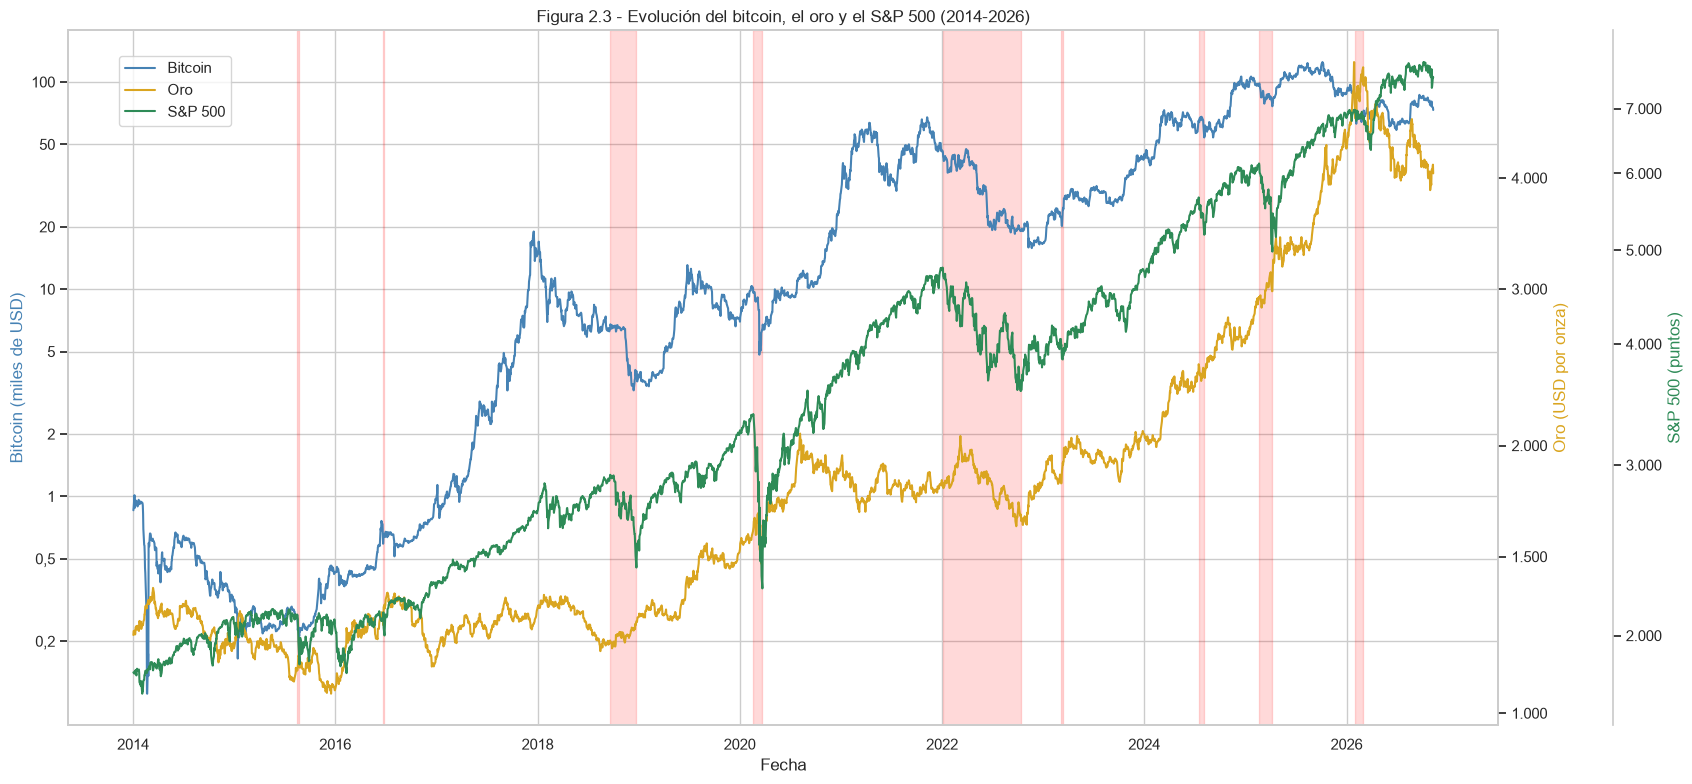

In [380]:
# Figura 2.3: evolución del bitcoin, el oro y el S&P 500 con tres ejes superpuestos (datos diarios).

fig, ax1 = plt.subplots(figsize=(17, 8))

# Eje 1 (izquierda): bitcoin en miles de USD
ax1.plot(df_btc.index, df_btc["Último"] / 1000, color="steelblue", linewidth=1.5, label="Bitcoin")
ax1.set_yscale("log")
ax1.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
ax1.set_yticklabels(["0,2", "0,5", "1", "2", "5", "10", "20", "50", "100"])
ax1.minorticks_off()
ax1.set_ylabel("Bitcoin (miles de USD)", color="steelblue")

# Eje 2 (derecha): oro en USD por onza
ax2 = ax1.twinx()
ax2.plot(df_oro.index, df_oro["Último"], color="goldenrod", linewidth=1.5, label="Oro")
ax2.set_yscale("log")
ax2.set_yticks([1000, 1500, 2000, 3000, 4000])
ax2.set_yticklabels(["1.000", "1.500", "2.000", "3.000", "4.000"])
ax2.minorticks_off()
ax2.set_ylabel("Oro (USD por onza)", color="goldenrod")
ax2.grid(False)

# Eje 3 (derecha, desplazado): S&P 500 en puntos
ax3 = ax1.twinx()
ax3.spines["right"].set_position(("axes", 1.08))
ax3.plot(df_sp500.index, df_sp500["Último"], color="seagreen", linewidth=1.5, label="S&P 500")
ax3.set_yscale("log")
ax3.set_yticks([2000, 3000, 4000, 5000, 6000, 7000])
ax3.set_yticklabels(["2.000", "3.000", "4.000", "5.000", "6.000", "7.000"])
ax3.minorticks_off()
ax3.set_ylabel("S&P 500 (puntos)", color="seagreen")
ax3.grid(False)

# Periodos de crisis
for i in range(len(crisis)):
    ax1.axvspan(crisis["inicio"][i], crisis["fin"][i], color="red", alpha=0.15)

ax1.set_title("Figura 2.3 - Evolución del bitcoin, el oro y el S&P 500 (2014-2026)")
ax1.set_xlabel("Fecha")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
plt.tight_layout()
plt.show()

Correlacion Bitcoin-Oro

In [381]:
# Variación diaria (%) recalculada sobre las fechas comunes, para que los tres activos
# comparen siempre el mismo par de días (la de Investing del bitcoin incluye fines de semana).

var_diaria = pd.DataFrame(index=df_btc.index[1:])

for nombre, tabla in [("bitcoin", df_btc), ("sp500", df_sp500), ("oro", df_oro)]:
    cierre = tabla["Último"].values
    var_diaria[nombre] = (cierre[1:] - cierre[:-1]) / cierre[:-1] * 100

var_diaria.head()

,bitcoin,sp500,oro
Fecha,,,
2014-01-03,3.197573,-0.032751,1.022558
2014-01-06,14.519959,-0.251174,0.097017
2014-01-07,-13.113459,0.607620,-0.482998
2014-01-08,6.693942,-0.021764,-0.499140
2014-01-09,-0.191734,0.032653,0.170477


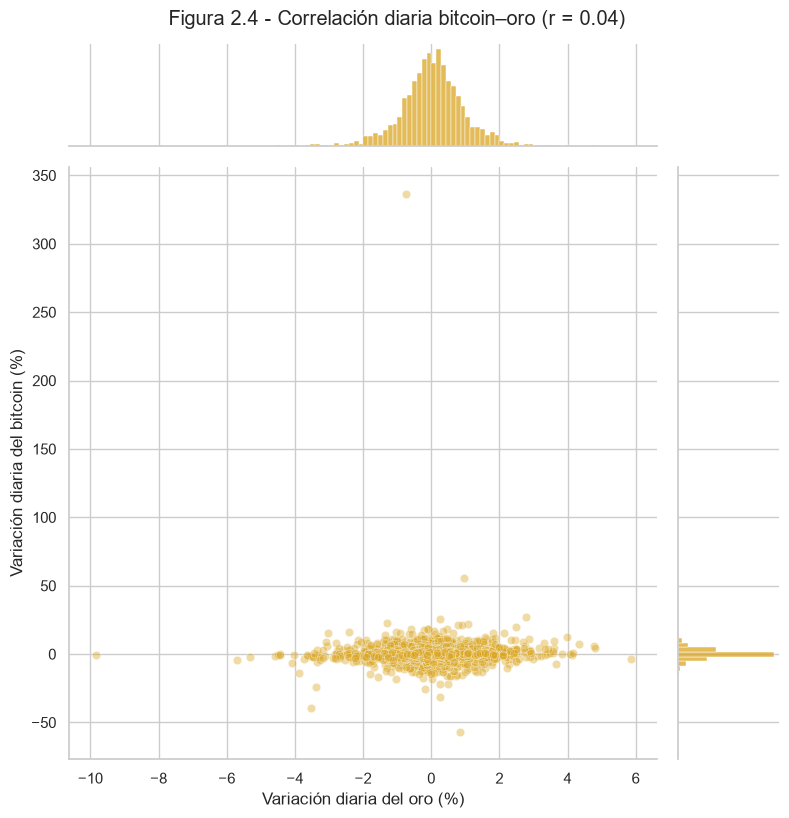

In [382]:
corr_oro = var_diaria["bitcoin"].corr(var_diaria["oro"]).round(2)

g = sns.jointplot(x=var_diaria["oro"], y=var_diaria["bitcoin"],
                  color="goldenrod", height=8, alpha=0.4)
g.set_axis_labels("Variación diaria del oro (%)", "Variación diaria del bitcoin (%)")
g.figure.suptitle(f"Figura 2.4 - Correlación diaria bitcoin–oro (r = {corr_oro})", y=1.02)
plt.show()

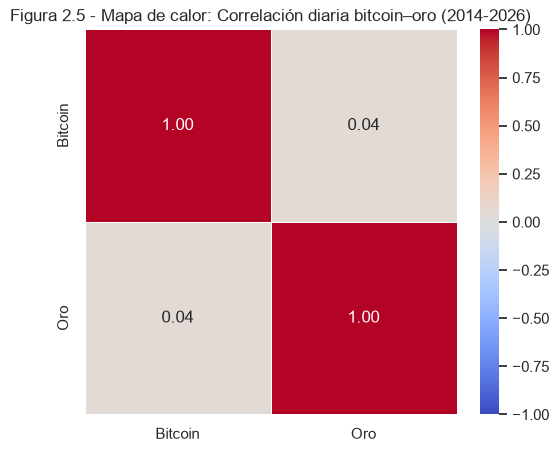

In [383]:
# Mapa de calor: correlación de las variaciones diarias bitcoin–oro.

corr_btc_oro = var_diaria[["bitcoin", "oro"]].rename(columns={"bitcoin": "Bitcoin", "oro": "Oro"}).corr()

f, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_btc_oro,
            annot=True,
            fmt=".2f",
            linewidths=.5,
            ax=ax,
            vmin=-1,
            vmax=1,
            cmap="coolwarm")

ax.set_title("Figura 2.5 - Mapa de calor: Correlación diaria bitcoin–oro (2014-2026)")
plt.show()

Correlacion con el SP500

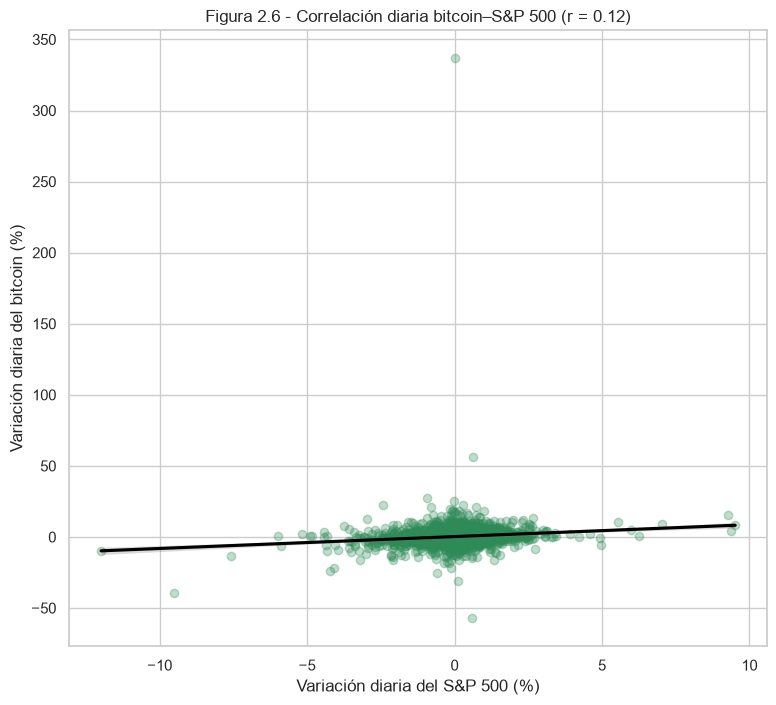

In [384]:
corr_sp500 = var_diaria["bitcoin"].corr(var_diaria["sp500"]).round(2)

plt.figure(figsize=(9, 8))
sns.regplot(x=var_diaria["sp500"], y=var_diaria["bitcoin"],
            scatter_kws={"alpha": 0.3, "color": "seagreen"},
            line_kws={"color": "black"})

plt.title(f"Figura 2.6 - Correlación diaria bitcoin–S&P 500 (r = {corr_sp500})")
plt.xlabel("Variación diaria del S&P 500 (%)")
plt.ylabel("Variación diaria del bitcoin (%)")
plt.show()

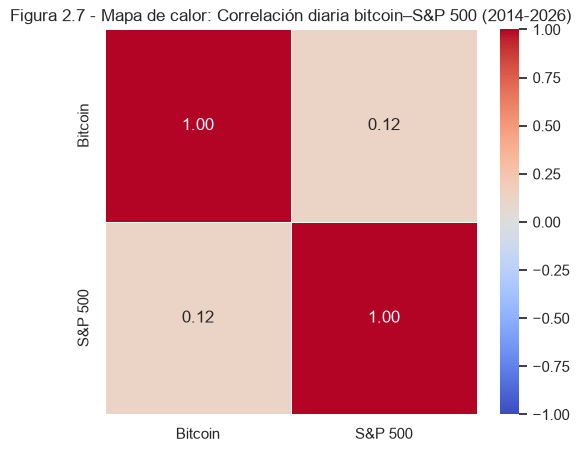

In [385]:
# Mapa de calor: correlación de las variaciones diarias bitcoin–S&P 500.

corr_btc_sp500 = var_diaria[["bitcoin", "sp500"]].rename(columns={"bitcoin": "Bitcoin", "sp500": "S&P 500"}).corr()

f, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_btc_sp500,
            annot=True,
            fmt=".2f",
            linewidths=.5,
            ax=ax,
            vmin=-1,
            vmax=1,
            cmap="coolwarm")

ax.set_title("Figura 2.7 - Mapa de calor: Correlación diaria bitcoin–S&P 500 (2014-2026)")
plt.show()

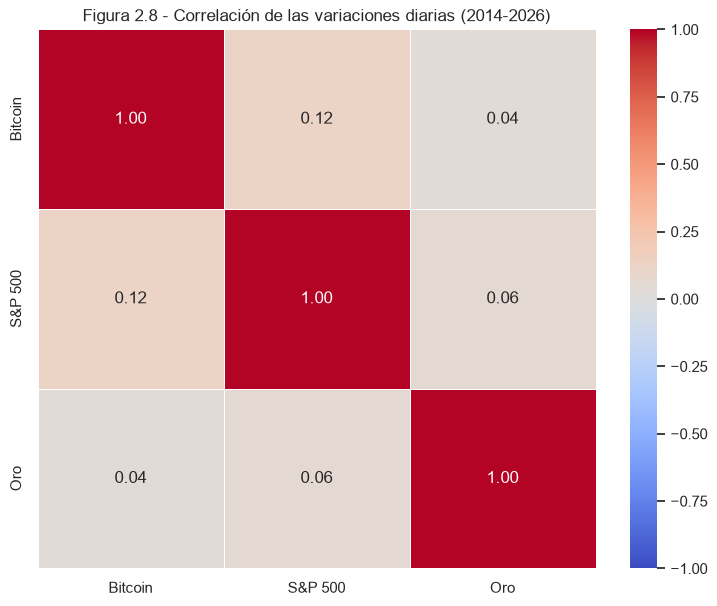

In [386]:
# Figura 2.8: matriz de correlación de las variaciones diarias de los tres activos.

correlaciones = var_diaria.rename(columns={"bitcoin": "Bitcoin", "sp500": "S&P 500", "oro": "Oro"}).corr()

f, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlaciones,
            annot=True,
            fmt=".2f",
            linewidths=.5,
            ax=ax,
            vmin=-1,
            vmax=1,
            cmap="coolwarm")

ax.set_title("Figura 2.8 - Correlación de las variaciones diarias (2014-2026)")
plt.show()

3.- Comportamiento de los tres activos en cada crisis

La tabla muestra la diferencia entre la variación del bitcoin y la del oro y la del S&P 500 (cuanto más cerca de 0, más parecido fue su comportamiento). El gráfico muestra la subida o bajada (%) de cada activo en cada crisis.

In [387]:
# Diferencia (en puntos porcentuales) entre la variación del bitcoin y la de cada activo en cada crisis.
# Se parte de la tabla resumen de la H1.

diferencias = pd.DataFrame({
    "Bitcoin - Oro": resumen_h1["bitcoin"] - resumen_h1["oro"],
    "Bitcoin - S&P 500": resumen_h1["bitcoin"] - resumen_h1["sp500"]
}).round(2)

diferencias.loc["Media"] = diferencias.mean().round(2)
diferencias

,Bitcoin - Oro,Bitcoin - S&P 500
crisis,,
Crash bursátil chino,-16.31,-3.07
Brexit,-1.63,9.19
Subida de tipos FED 2018,-43.09,-18.18
COVID,-29.05,1.25
Inflación y subida de tipos,-51.63,-33.31
Crisis bancaria EE. UU.,5.57,14.48
Carry trade del yen,-14.63,-8.53
Aranceles EE. UU.,-22.78,-2.14
Conflicto con Irán,-29.43,-14.92


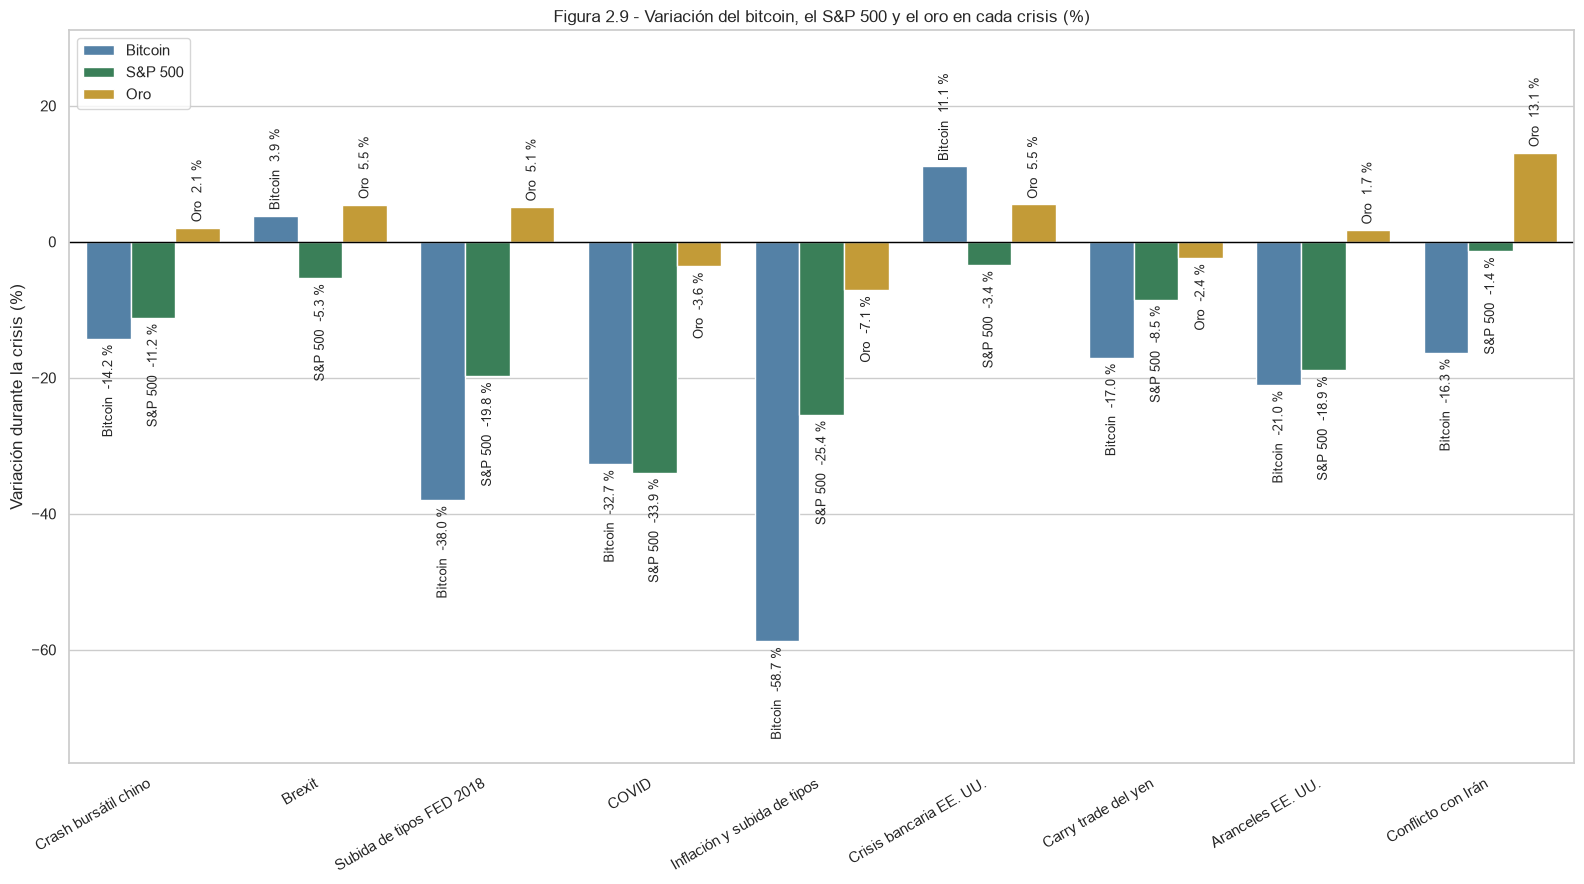

In [388]:
# Figura 2.9: variación (%) del bitcoin, el oro y el S&P 500 en cada crisis.

# Formato largo para seaborn: una fila por crisis y activo.
var_largo = resumen_h1.rename(columns={"bitcoin": "Bitcoin", "oro": "Oro", "sp500": "S&P 500"})
var_largo = var_largo.rename_axis("crisis").reset_index().melt(
    id_vars="crisis", var_name="activo", value_name="variacion")

activos = ["Bitcoin", "S&P 500", "Oro"]

plt.figure(figsize=(16, 9))
ax = sns.barplot(data=var_largo, x="crisis", y="variacion", hue="activo",
                 hue_order=activos,
                 palette={"Bitcoin": "steelblue", "S&P 500": "seagreen", "Oro": "goldenrod"})

# Etiqueta sobre cada barra con el nombre del activo y su variación (%).
# Cada "contenedor" agrupa las barras de un activo, en el mismo orden que hue_order.
for contenedor, activo in zip(ax.containers, activos):
    etiquetas = [f"{activo}  {valor:.1f} %" for valor in contenedor.datavalues]
    ax.bar_label(contenedor, labels=etiquetas, rotation=90, padding=4, fontsize=9)

ax.margins(y=0.25)   # espacio extra arriba y abajo para que quepan las etiquetas
plt.axhline(0, color="black", linewidth=1)
plt.xticks(rotation=30, ha="right")
plt.title("Figura 2.9 - Variación del bitcoin, el S&P 500 y el oro en cada crisis (%)")
plt.ylabel("Variación durante la crisis (%)")
plt.xlabel("")
plt.legend(title="")
plt.tight_layout()
plt.show()